# 03 Auswertung

Ziel: Teilfragen 1 und 2 beantworten: Wie entwickeln sich Umsatz, Gewinn und Marge über die Zeit, und welche Kategorien, Produkte und Filialtypen tragen am stärksten zum Gewinn bei? Grundlage sind die bereinigten Daten aus Notebook 02.

In [1]:
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("sqlite:///../data/processed/maven_toys.db")
connection = engine.connect()

sales_full = pd.read_sql("SELECT * FROM sales_full", connection, parse_dates=["Date"])
inventory_full = pd.read_sql("SELECT * FROM inventory_full", connection)

In [2]:
sales_full.info()

<class 'pandas.DataFrame'>
RangeIndex: 829262 entries, 0 to 829261
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Sale_ID           829262 non-null  int64         
 1   Date              829262 non-null  datetime64[us]
 2   Units             829262 non-null  int64         
 3   Product_ID        829262 non-null  int64         
 4   Product_Name      829262 non-null  str           
 5   Product_Category  829262 non-null  str           
 6   Product_Cost      829262 non-null  float64       
 7   Product_Price     829262 non-null  float64       
 8   Store_ID          829262 non-null  int64         
 9   Store_Name        829262 non-null  str           
 10  Store_City        829262 non-null  str           
 11  Store_Location    829262 non-null  str           
 12  Revenue           829262 non-null  float64       
 13  Total_Cost        829262 non-null  float64       
 14  Profit         

## 1. Entwicklung über die Zeit
Umsatz, Gewinn und Marge werden pro Monat zusammengefasst. Die Daten reichen von Januar 2022 bis September 2023, also 21 Monate.

In [3]:
query_monthly = """
SELECT
    strftime('%Y-%m', Date) AS Month,
    ROUND(SUM(Revenue), 2) AS Revenue,
    ROUND(SUM(Profit), 2) AS Profit,
    ROUND(SUM(Profit) / SUM(Revenue) * 100, 1) AS Margin_Pct
FROM sales_full
GROUP BY Month
ORDER BY Month
"""

monthly = pd.read_sql(query_monthly, connection)
monthly

,Month,Revenue,Profit,Margin_Pct
0,2022-01,542554.91,167126.0,30.8
1,2022-02,541351.65,161861.0,29.9
2,2022-03,589485.19,173992.0,29.5
3,2022-04,681072.98,190099.0,27.9
4,2022-05,672369.90,186894.0,27.8
5,2022-06,661980.22,189815.0,28.7
6,2022-07,556034.23,176922.0,31.8
7,2022-08,489422.73,158931.0,32.5
8,2022-09,585844.04,166397.0,28.4
9,2022-10,623874.39,178799.0,28.7


### Umsatz und Gewinn im Zeitverlauf

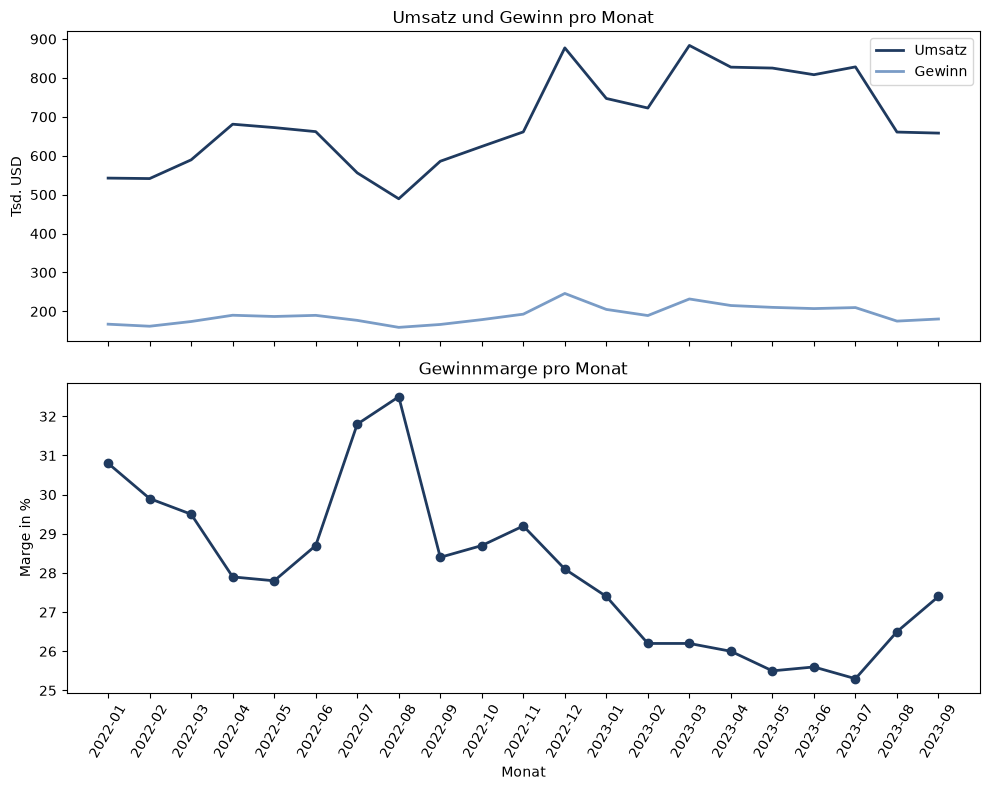

In [4]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.plot(monthly["Month"], monthly["Revenue"] / 1000, label="Umsatz", color="#1f3a5f", linewidth=2)
ax1.plot(monthly["Month"], monthly["Profit"] / 1000, label="Gewinn", color="#7a9cc6", linewidth=2)
ax1.set_title("Umsatz und Gewinn pro Monat")
ax1.set_ylabel("Tsd. USD")
ax1.legend()

ax2.plot(monthly["Month"], monthly["Margin_Pct"], color="#1f3a5f", linewidth=2, marker="o")
ax2.set_title("Gewinnmarge pro Monat")
ax2.set_ylabel("Marge in %")
ax2.set_xlabel("Monat")
ax2.tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

### Vergleich Januar bis September
Um die Jahre fair zu vergleichen, werden nur die Monate Januar bis September betrachtet, weil 2023 nur bis Ende September reicht.

In [5]:
query_yoy = """
SELECT
    strftime('%Y', Date) AS Year,
    ROUND(SUM(Revenue), 2) AS Revenue,
    ROUND(SUM(Profit), 2) AS Profit,
    ROUND(SUM(Profit) / SUM(Revenue) * 100, 1) AS Margin_Pct
FROM sales_full
WHERE strftime('%m', Date) <= '09'
GROUP BY Year
ORDER BY Year
"""

yoy = pd.read_sql(query_yoy, connection)
yoy

,Year,Revenue,Profit,Margin_Pct
0,2022,5320115.85,1572037.0,29.5
1,2023,6962074.27,1824242.0,26.2


### Befunde Zeitverlauf
- Vergleich Januar bis September: Der Umsatz stieg 2023 gegenüber 2022 um rund 31 % (5,32 auf 6,96 Mio. USD), der Gewinn nur um rund 16 % (1,57 auf 1,82 Mio. USD).
- Die Marge sank von 29,5 % auf 26,2 %.
- Die Marge lag im August 2022 mit 32,5 % am höchsten, im Juli 2023 mit 25,3 % am niedrigsten und erholte sich bis September 2023 leicht auf 27,4 %.
- Saisonalität: Spitze im Dezember 2022 (rund 877.000 USD Umsatz), schwache Sommermonate 2022 (August rund 489.000 USD). Der höchste Monat insgesamt ist der März 2023 (rund 884.000 USD).
- Preise und Einkaufspreise sind pro Produkt konstant. Der Margenrückgang kann deshalb nur auf einer Verschiebung im Produktmix beruhen. Das wird in Teilfrage 2 geprüft.

## 2. Profitabilität nach Kategorie
Der Margenrückgang soll durch eine Verschiebung im Produktmix erklärt werden. Dazu werden Umsatz, Gewinn und Marge pro Produktkategorie für Januar bis September 2022 und 2023 verglichen.

In [6]:
query_category = """
SELECT
    Product_Category AS Category,
    strftime('%Y', Date) AS Year,
    ROUND(SUM(Revenue), 2) AS Revenue,
    ROUND(SUM(Profit), 2) AS Profit,
    ROUND(SUM(Profit) / SUM(Revenue) * 100, 1) AS Margin_Pct
FROM sales_full
WHERE strftime('%m', Date) <= '09'
GROUP BY Category, Year
ORDER BY Category, Year
"""

category = pd.read_sql(query_category, connection)
category

,Category,Year,Revenue,Profit,Margin_Pct
0,Art & Crafts,2022,511146.27,144660.0,28.3
1,Art & Crafts,2023,1798723.38,480405.0,26.7
2,Electronics,2022,1117477.73,537290.0,48.1
3,Electronics,2023,806312.06,327030.0,40.6
4,Games,2022,829956.68,261807.0,31.5
5,Games,2023,998192.68,295612.0,29.6
6,Sports & Outdoors,2022,841765.18,184973.0,22.0
7,Sports & Outdoors,2023,1052931.70,250692.0,23.8
8,Toys,2022,2019769.99,443307.0,21.9
9,Toys,2023,2305914.45,470503.0,20.4


### Befunde Kategorien
- Electronics hat mit 48,1 % (2022) und 40,6 % (2023) die mit Abstand höchste Marge, verliert aber Umsatz (minus 28 %) und Gewinn (minus 39 %). Der Gewinnanteil sinkt von 34 % auf 18 %.
- Art & Crafts wächst von 0,51 auf 1,80 Mio. USD Umsatz (rund das 3,5-fache) und ist 2023 mit 26 % des Gewinns die größte Gewinnquelle.
- Toys ist mit 38 % bzw. 33 % des Umsatzes die größte Kategorie, hat aber mit rund 20 bis 22 % die niedrigste Marge.
- Sports & Outdoors ist die einzige Kategorie mit steigender Marge (22,0 auf 23,8 %).
- Der Rückgang der Gesamtmarge wird nur zu etwa einem Drittel durch die Verschiebung zwischen den Kategorien erklärt, zu etwa zwei Dritteln durch sinkende Margen innerhalb der Kategorien. Das wird auf Produktebene geprüft.

## 3. Profitabilität nach Produkt
Für jedes Produkt wird der Gewinn von Januar bis September 2022 und 2023 verglichen, um zu sehen, welche Produkte den Zuwachs und welche den Rückgang tragen.

In [7]:
query_product = """
SELECT
    Product_Name,
    Product_Category,
    ROUND(SUM(CASE WHEN strftime('%Y', Date) = '2022' THEN Profit ELSE 0 END), 0) AS Profit_2022,
    ROUND(SUM(CASE WHEN strftime('%Y', Date) = '2023' THEN Profit ELSE 0 END), 0) AS Profit_2023
FROM sales_full
WHERE strftime('%m', Date) <= '09'
GROUP BY Product_Name, Product_Category
"""

products_yoy = pd.read_sql(query_product, connection)
products_yoy["Profit_Change"] = products_yoy["Profit_2023"] - products_yoy["Profit_2022"]
products_yoy.sort_values("Profit_Change")

,Product_Name,Product_Category,Profit_2022,Profit_2023,Profit_Change
5,Colorbuds,Electronics,497096.0,233248.0,-263848.0
0,Action Figure,Toys,176976.0,125538.0,-51438.0
16,Kids Makeup Kit,Art & Crafts,77142.0,50622.0,-26520.0
6,Dart Gun,Sports & Outdoors,64508.0,40992.0,-23516.0
30,Splash Balls,Sports & Outdoors,31647.0,23208.0,-8439.0
19,Mini Basketball Hoop,Sports & Outdoors,20352.0,14560.0,-5792.0
26,PlayDoh Toolkit,Art & Crafts,13070.0,7662.0,-5408.0
31,Supersoaker Water Gun,Sports & Outdoors,10581.0,7839.0,-2742.0
33,Toy Robot,Electronics,26730.0,24230.0,-2500.0
9,Dinosaur Figures,Toys,50484.0,48112.0,-2372.0


### Befunde Produkte
- Colorbuds (Electronics) ist der größte Einzelfaktor: Der Gewinn sinkt von 497.000 auf 233.000 USD (minus 53 %). Das Produkt machte 2022 rund 32 % des gesamten Gewinns aus, 2023 nur noch rund 13 %.
- Der Zuwachs bei Art & Crafts wird vor allem von Barrel O' Slime, Magic Sand, Etch A Sketch und Playfoam getragen. Etch A Sketch, Playfoam und Foam Disk Launcher hatten 2022 keinen Gewinn und wurden vermutlich erst später eingeführt.
- Weitere Gewinnrückgänge: Action Figure (minus 51.000), Kids Makeup Kit (minus 26.500), Dart Gun (minus 23.500).
- Der Margenrückgang ergibt sich damit aus dem Einbruch eines margenstarken Produkts und dem Wachstum margenschwächerer Produkte.

### Erster und letzter Verkaufstag je Produkt
Um zu prüfen, ob Produkte neu ins Sortiment kamen, wird pro Produkt der erste und der letzte Verkaufstag bestimmt.

In [8]:
query_dates = """
SELECT
    Product_Name,
    Product_Category,
    SUBSTR(MIN(Date), 1, 10) AS First_Sale,
    SUBSTR(MAX(Date), 1, 10) AS Last_Sale
FROM sales_full
GROUP BY Product_Name, Product_Category
ORDER BY First_Sale DESC
"""

product_dates = pd.read_sql(query_dates, connection)
product_dates

,Product_Name,Product_Category,First_Sale,Last_Sale
0,Playfoam,Art & Crafts,2023-08-17,2023-09-30
1,Foam Disk Launcher,Sports & Outdoors,2023-03-07,2023-09-30
2,Etch A Sketch,Art & Crafts,2022-11-11,2023-09-30
3,Mr. Potatohead,Toys,2022-08-01,2023-09-30
4,Magic Sand,Art & Crafts,2022-07-29,2023-09-30
5,Gamer Headphones,Electronics,2022-07-14,2023-09-30
6,Plush Pony,Toys,2022-06-14,2023-09-30
7,PlayDoh Playset,Art & Crafts,2022-05-17,2023-09-29
8,Jenga,Games,2022-05-16,2023-09-30
9,Supersoaker Water Gun,Sports & Outdoors,2022-03-19,2023-09-30


### Neue Produkte und Bestandsprodukte
Produkte, die erst nach dem 01.01.2022 erstmals verkauft wurden, gelten als neu. Es wird verglichen, wie viel Gewinn neue Produkte und Bestandsprodukte im Vergleich Januar bis September 2022 und 2023 beigetragen haben.

In [9]:
new_products = product_dates.loc[product_dates["First_Sale"] > "2022-01-01", "Product_Name"]

products_yoy["Is_New"] = products_yoy["Product_Name"].isin(new_products)

products_yoy.groupby("Is_New")[["Profit_2022", "Profit_2023", "Profit_Change"]].sum()

,Profit_2022,Profit_2023,Profit_Change
Is_New,,,
False,1463078.0,1362907.0,-100171.0
True,108959.0,461335.0,352376.0


### Befunde Sortiment
- 11 von 35 Produkten wurden erst nach dem 01.01.2022 eingeführt, die übrigen 24 sind seit Beginn dabei. Kein Produkt wurde bis Ende September 2023 aus dem Sortiment genommen.
- Im Vergleich Januar bis September stieg der Gewinn der neuen Produkte um rund 352.000 USD, während der Gewinn der Bestandsprodukte um rund 100.000 USD sank. Das Wachstum stammt damit vollständig aus der Sortimentserweiterung.
- Der Rückgang im Bestand geht vor allem auf Colorbuds zurück (minus 264.000 USD).
- Einschränkung: Weil das Sortiment 2023 größer ist, ist der Vergleich der beiden Zeiträume nicht vollständig gleichartig.

### Colorbuds und Gamer Headphones im Monatsverlauf
Colorbuds ist der größte Einzelfaktor für den Gewinnrückgang im Bestand. Der monatliche Gewinn wird zusammen mit den Gamer Headphones (Einführung am 14.07.2022, ebenfalls Electronics) betrachtet, um zu sehen, wann der Einbruch passiert und ob ein Zusammenhang besteht.

In [10]:
query_colorbuds = """
SELECT
    strftime('%Y-%m', Date) AS Month,
    Product_Name,
    ROUND(SUM(Profit), 0) AS Profit
FROM sales_full
WHERE Product_Name IN ('Colorbuds', 'Gamer Headphones')
GROUP BY Month, Product_Name
ORDER BY Month
"""

electronics = pd.read_sql(query_colorbuds, connection)
electronics_wide = electronics.pivot(index="Month", columns="Product_Name", values="Profit").fillna(0)
electronics_wide

Product_Name,Colorbuds,Gamer Headphones
Month,,
2022-01,64880.0,0.0
2022-02,61016.0,0.0
2022-03,62744.0,0.0
2022-04,58136.0,0.0
2022-05,55792.0,0.0
2022-06,52048.0,0.0
2022-07,52088.0,1404.0
2022-08,50944.0,5268.0
2022-09,39448.0,6792.0


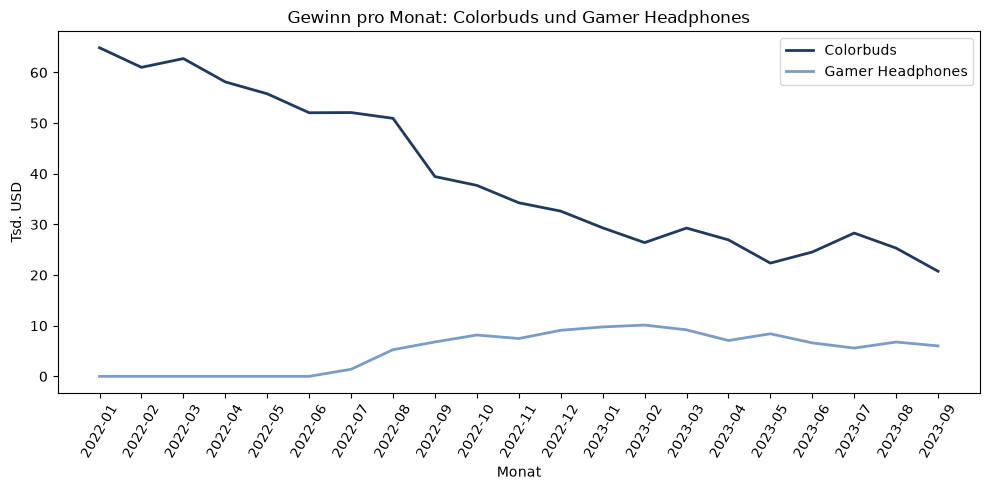

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(electronics_wide.index, electronics_wide["Colorbuds"] / 1000, label="Colorbuds", color="#1f3a5f", linewidth=2)
ax.plot(electronics_wide.index, electronics_wide["Gamer Headphones"] / 1000, label="Gamer Headphones", color="#7a9cc6", linewidth=2)

ax.set_title("Gewinn pro Monat: Colorbuds und Gamer Headphones")
ax.set_xlabel("Monat")
ax.set_ylabel("Tsd. USD")
ax.tick_params(axis="x", rotation=60)
ax.legend()

plt.tight_layout()
plt.show()

### Befunde Colorbuds
- Der Gewinn von Colorbuds sinkt über den gesamten Zeitraum von rund 64.900 USD im Januar 2022 auf rund 20.800 USD im September 2023 (minus 68 %). Der Rückgang begann bereits vor der Einführung der Gamer Headphones (14.07.2022).
- Ein deutlicher Knick liegt im September 2022 (von 50.900 auf 39.400 USD), danach sinkt der Gewinn weiter.
- Die Gamer Headphones erreichen höchstens rund 10.000 USD Gewinn pro Monat und gleichen den Rückgang nur zu einem kleinen Teil aus. Ab Februar 2023 sinken beide Produkte.
- Eine Verlagerung von Colorbuds auf die Gamer Headphones ist damit allenfalls ein Teil der Erklärung. Die Ursache des Rückgangs lässt sich mit den vorliegenden Daten nicht klären.

## 4. Profitabilität nach Filialtyp
Die Filialen sind drei Standorttypen zugeordnet (Residential, Commercial, Downtown). Verglichen werden Umsatz, Gewinn und Marge für Januar bis September 2022 und 2023, außerdem der Gewinn pro Filiale.

In [12]:
query_location = """
SELECT
    Store_Location,
    strftime('%Y', Date) AS Year,
    COUNT(DISTINCT Store_ID) AS Stores,
    ROUND(SUM(Revenue), 0) AS Revenue,
    ROUND(SUM(Profit), 0) AS Profit,
    ROUND(SUM(Profit) / SUM(Revenue) * 100, 1) AS Margin_Pct,
    ROUND(SUM(Profit) / COUNT(DISTINCT Store_ID), 0) AS Profit_per_Store
FROM sales_full
WHERE strftime('%m', Date) <= '09'
GROUP BY Store_Location, Year
ORDER BY Store_Location, Year
"""

location = pd.read_sql(query_location, connection)
location

,Store_Location,Year,Stores,Revenue,Profit,Margin_Pct,Profit_per_Store
0,Airport,2022,3,465067.0,148413.0,31.9,49471.0
1,Airport,2023,3,639467.0,173039.0,27.1,57680.0
2,Commercial,2022,12,1239775.0,376884.0,30.4,31407.0
3,Commercial,2023,12,1552272.0,408965.0,26.3,34080.0
4,Downtown,2022,29,2992034.0,869573.0,29.1,29985.0
5,Downtown,2023,29,3992417.0,1030820.0,25.8,35546.0
6,Residential,2022,6,623240.0,177167.0,28.4,29528.0
7,Residential,2023,6,777918.0,211418.0,27.2,35236.0


### Befunde Filialtyp
- Downtown ist mit 29 von 50 Filialen der wichtigste Standorttyp und erzielt 2023 rund 57 % des Gewinns.
- Pro Filiale ist Airport am profitabelsten: 2023 rund 57.700 USD Gewinn je Filiale gegenüber rund 35.500 USD in Downtown. Wegen nur drei Filialen ist die Aussage mit Vorsicht zu lesen.
- Commercial wächst beim Gewinn pro Filiale am schwächsten (plus 8,5 %), Residential am stärksten gemeinsam mit Downtown (jeweils rund plus 19 %).
- Die Marge sinkt in allen vier Standorttypen (Airport minus 4,8, Commercial minus 4,1, Downtown minus 3,3, Residential minus 1,2 Prozentpunkte). Der Margenrückgang ist daher kein Standortproblem, sondern liegt am Produktmix.

### Profitabilität nach Stadt
Gewinn, Marge und Gewinn pro Filiale je Stadt über den gesamten Zeitraum, sortiert nach Gewinn.

In [13]:
query_city = """
SELECT
    Store_City,
    COUNT(DISTINCT Store_ID) AS Stores,
    ROUND(SUM(Profit), 0) AS Profit,
    ROUND(SUM(Profit) / SUM(Revenue) * 100, 1) AS Margin_Pct,
    ROUND(SUM(Profit) / COUNT(DISTINCT Store_ID), 0) AS Profit_per_Store
FROM sales_full
GROUP BY Store_City
ORDER BY Profit DESC
"""

city = pd.read_sql(query_city, connection)
city

,Store_City,Stores,Profit,Margin_Pct,Profit_per_Store
0,Cuidad de Mexico,4,465558.0,28.2,116390.0
1,Guadalajara,4,368930.0,27.9,92233.0
2,Monterrey,4,346729.0,27.5,86682.0
3,Hermosillo,3,263608.0,29.2,87869.0
4,Guanajuato,3,235047.0,27.0,78349.0
5,Puebla,3,229694.0,28.4,76565.0
6,Mexicali,2,175048.0,29.9,87524.0
7,Xalapa,2,163720.0,26.8,81860.0
8,Saltillo,2,163248.0,28.2,81624.0
9,Toluca,2,162702.0,25.7,81351.0


### Befunde Stadt
- Ciudad de México (4 Filialen) hat den höchsten Gewinn (rund 465.600 USD, etwa 12 % des Gesamtgewinns) und mit rund 116.400 USD pro Filiale den höchsten Gewinn je Filiale, rund 26 % vor Guadalajara.
- Die drei größten Städte (Ciudad de México, Guadalajara, Monterrey) erzielen zusammen rund 29 % des Gewinns mit 12 von 50 Filialen.
- Der Gewinn pro Filiale reicht von rund 56.800 USD (Cuernavaca) bis rund 116.400 USD (Ciudad de México).
- Die Margen liegen zwischen 24,6 % (Oaxaca) und 33,1 % (Morelia). Bei Städten mit nur einer Filiale ist die Aussagekraft begrenzt.
- Datenhinweis: Die Stadt heißt in der Quelle "Cuidad de Mexico" (Tippfehler), durchgängig gleich geschrieben.

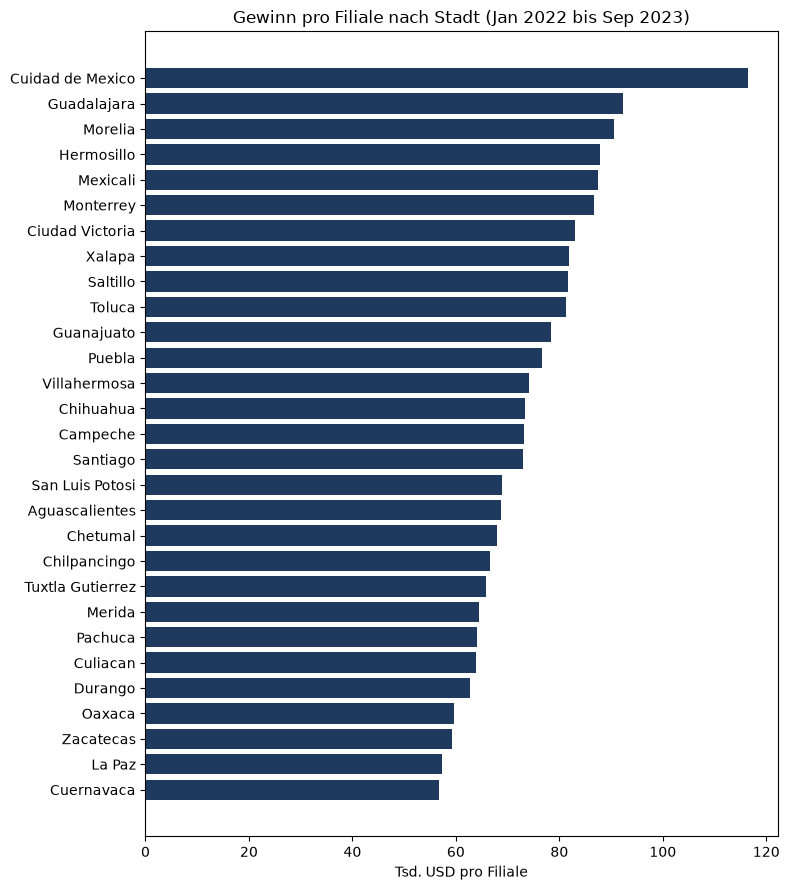

In [14]:
city_sorted = city.sort_values("Profit_per_Store")

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(city_sorted["Store_City"], city_sorted["Profit_per_Store"] / 1000, color="#1f3a5f")

ax.set_title("Gewinn pro Filiale nach Stadt (Jan 2022 bis Sep 2023)")
ax.set_xlabel("Tsd. USD pro Filiale")

plt.tight_layout()
plt.show()

## 5. Konzentration: ABC-Analyse der Produkte
Die Produkte werden nach ihrem Gewinn über den gesamten Zeitraum sortiert und in Klassen eingeteilt: A-Produkte erzeugen die ersten 80 % des Gewinns, B-Produkte die nächsten 15 %, C-Produkte die letzten 5 %.

In [15]:
product_profit = (
    sales_full.groupby("Product_Name")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

product_profit["Share_Pct"] = product_profit["Profit"] / product_profit["Profit"].sum() * 100
product_profit["Cumulative_Pct"] = product_profit["Share_Pct"].cumsum()
product_profit["ABC_Class"] = pd.cut(
    product_profit["Cumulative_Pct"] - product_profit["Share_Pct"],
    bins=[-1, 80, 95, 101],
    labels=["A", "B", "C"],
)

product_profit.round(1)

,Product_Name,Profit,Share_Pct,Cumulative_Pct,ABC_Class
0,Colorbuds,834944.0,20.8,20.8,A
1,Action Figure,347748.0,8.7,29.5,A
2,Lego Bricks,298685.0,7.4,36.9,A
3,Deck Of Cards,252102.0,6.3,43.2,A
4,Glass Marbles,187590.0,4.7,47.9,A
5,Barrel O' Slime,183326.0,4.6,52.4,A
6,Kids Makeup Kit,146598.0,3.7,56.1,A
7,Nerf Gun,132715.0,3.3,59.4,A
8,Dart Gun,126352.0,3.1,62.5,A
9,Etch A Sketch,121680.0,3.0,65.6,A


In [16]:
product_profit.groupby("ABC_Class", observed=True).agg(
    Products=("Product_Name", "count"),
    Profit=("Profit", "sum"),
)

,Products,Profit
ABC_Class,,
A,16,3297939.0
B,9,531014.0
C,10,185076.0


### Befunde ABC-Analyse
- 16 von 35 Produkten (A-Klasse) erzeugen rund 82 % des Gewinns, 9 Produkte (B) rund 13 % und 10 Produkte (C) rund 5 %. Die Konzentration ist damit moderat.
- Colorbuds erzeugt allein 20,8 % des Gesamtgewinns, mehr als doppelt so viel wie das zweitplatzierte Produkt (Action Figure, 8,7 %). Die fünf besten Produkte kommen auf 47,9 %, die zehn besten auf 65,6 %.
- Mit Etch A Sketch, Magic Sand und Gamer Headphones gehören drei Neueinführungen zur A-Klasse.
- Die C-Klasse enthält vier Spiele (Monopoly, Chutes & Ladders, Uno, Classic Dominoes) sowie junge Produkte, bei denen die kurze Verkaufsdauer den geringen Gewinn mit erklärt.
- Einschränkung: Die Einteilung basiert auf dem Gewinn über den gesamten Zeitraum und berücksichtigt weder die Verkaufsdauer noch den Trend.

### Stabilität: Abhängigkeit von Colorbuds und Schwankung
Der Anteil von Colorbuds am monatlichen Gesamtgewinn zeigt, wie sich die Abhängigkeit von diesem Produkt entwickelt. Der Variationskoeffizient (Standardabweichung geteilt durch Mittelwert) misst, wie stark der Gewinn pro Monat schwankt.

In [17]:
colorbuds_share = (electronics_wide["Colorbuds"] / monthly.set_index("Month")["Profit"] * 100).round(1)
print(colorbuds_share)

cv = monthly["Profit"].std() / monthly["Profit"].mean()
print("Variationskoeffizient des Monatsgewinns:", round(cv, 3))

Month
2022-01    38.8
2022-02    37.7
2022-03    36.1
2022-04    30.6
2022-05    29.9
2022-06    27.4
2022-07    29.4
2022-08    32.1
2022-09    23.7
2022-10    21.1
2022-11    17.8
2022-12    13.3
2023-01    14.3
2023-02    13.9
2023-03    12.6
2023-04    12.5
2023-05    10.6
2023-06    11.8
2023-07    13.5
2023-08    14.5
2023-09    11.5
dtype: float64
Variationskoeffizient des Monatsgewinns: 0.12


### Befunde Stabilität
- Der Anteil von Colorbuds am monatlichen Gesamtgewinn sinkt von 38,8 % (Januar 2022) auf 13,3 % (Dezember 2022) und liegt 2023 stabil zwischen 10,6 % und 14,5 %. Die Abhängigkeit von einem einzelnen Produkt ist damit deutlich geringer als im Gesamtzeitraum (20,8 %, siehe ABC-Analyse).
- Der Anteilsrückgang hat zwei Ursachen, die diese Kennzahl nicht trennt: Colorbuds verliert selbst an Gewinn, und andere Produkte (v. a. Neueinführungen) gewinnen hinzu.
- Auffällig ist der Rückgang von August auf September 2022 (32,1 % auf 23,7 %).
- Der Variationskoeffizient des Monatsgewinns beträgt 0,12. Der Wert enthält Wachstumstrend und Saisonalität und misst daher nicht die reine Schwankung.

## Teilfrage 4: Lager und Kapitalbindung
Die Lagerdaten sind eine Momentaufnahme ohne Datum. Der Lagerwert (Stock_Value) ist der Bestand mal Einkaufskosten und zeigt, wie viel Kapital aktuell im Lager gebunden ist. Zuerst betrachten wir den Gesamtwert und die Verteilung nach Produktkategorie.

In [18]:
print(inventory_full.columns.tolist())

print("Gesamter Lagerwert:", round(inventory_full["Stock_Value"].sum()))

stock_category = (
    inventory_full.groupby("Product_Category")["Stock_Value"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
stock_category["Share_Pct"] = (stock_category["Stock_Value"] / stock_category["Stock_Value"].sum() * 100).round(1)
stock_category

['Store_ID', 'Store_Name', 'Store_City', 'Store_Location', 'Product_ID', 'Product_Name', 'Product_Category', 'Product_Cost', 'Product_Price', 'Stock_On_Hand', 'Stock_Value']
Gesamter Lagerwert: 300210


,Product_Category,Stock_Value,Share_Pct
0,Toys,99861.47,33.3
1,Art & Crafts,65075.65,21.7
2,Sports & Outdoors,53077.19,17.7
3,Games,51489.45,17.2
4,Electronics,30705.82,10.2


### Befunde Lagerwert nach Kategorie
- Im Lager sind insgesamt 300.210 USD gebunden (Momentaufnahme).
- Toys binden mit 33,3 % den größten Anteil, Electronics mit 10,2 % den kleinsten.
- Ob der Lagerwert angemessen ist, zeigt der Vergleich mit dem Absatz (Reichweite, nächster Schritt).

### Reichweite des Lagers
Die Reichweite gibt an, für wie viele Monate der Lagerwert reicht, wenn die Warenkosten der letzten drei Monate (Juli bis September 2023) als Maßstab dienen.

In [19]:
last_3_months = sales_full[sales_full["Date"] >= "2023-07-01"]

cost_per_month = (
    last_3_months.groupby("Product_Category")["Total_Cost"].sum() / 3
)

stock_category["Cost_per_Month"] = stock_category["Product_Category"].map(cost_per_month).round()
stock_category["Months_of_Stock"] = (stock_category["Stock_Value"] / stock_category["Cost_per_Month"]).round(1)
stock_category

,Product_Category,Stock_Value,Share_Pct,Cost_per_Month,Months_of_Stock
0,Toys,99861.47,33.3,199466.0,0.5
1,Art & Crafts,65075.65,21.7,129979.0,0.5
2,Sports & Outdoors,53077.19,17.7,86602.0,0.6
3,Games,51489.45,17.2,63031.0,0.8
4,Electronics,30705.82,10.2,48299.0,0.6


### Befunde Reichweite nach Kategorie
- Die Reichweite liegt in allen Kategorien zwischen 0,5 und 0,8 Monaten. Das Lager ist insgesamt sehr schlank.
- Games hat mit 0,8 Monaten die höchste, Toys und Art & Crafts haben mit 0,5 Monaten die niedrigste Reichweite. Die Unterschiede zwischen den Kategorien sind gering.
- Einschränkung: Die Lagerdaten sind eine Momentaufnahme ohne Datum. Die Reichweite ist daher eine Näherung.

### Reichweite je Produkt
Auf Produktebene prüfen wir, ob einzelne Produkte deutlich mehr oder weniger Reichweite haben als der Durchschnitt.

In [20]:
stock_product = (
    inventory_full.groupby("Product_Name")["Stock_Value"].sum().reset_index()
)
cost_product = last_3_months.groupby("Product_Name")["Total_Cost"].sum() / 3

stock_product["Cost_per_Month"] = stock_product["Product_Name"].map(cost_product)
stock_product["Months_of_Stock"] = (stock_product["Stock_Value"] / stock_product["Cost_per_Month"]).round(1)

stock_product.sort_values("Months_of_Stock", ascending=False).round(1)

,Product_Name,Stock_Value,Cost_per_Month,Months_of_Stock
19,Mini Basketball Hoop,2103.7,704.2,3.0
25,PlayDoh Playset,11544.5,6709.8,1.7
31,Supersoaker Water Gun,6150.9,3597.0,1.7
32,Teddy Bear,5308.2,3300.7,1.6
28,Plush Pony,4468.0,2873.8,1.6
9,Dinosaur Figures,24969.3,17016.2,1.5
34,Uno Card Game,961.6,677.0,1.4
26,PlayDoh Toolkit,5534.1,3847.7,1.4
3,Chutes & Ladders,2547.4,2034.6,1.3
4,Classic Dominoes,1925.6,1667.2,1.2


### Befunde Reichweite je Produkt
- Die höchste Reichweite hat Mini Basketball Hoop (3,0 Monate), gefolgt von PlayDoh Playset und Supersoaker Water Gun (je 1,7 Monate). Den größten Posten mit überdurchschnittlicher Bindung bildet Dinosaur Figures (24.969 USD Lagerwert, 1,5 Monate).
- Sehr niedrig ist die Reichweite bei Dino Egg (0,2 Monate) sowie bei Hot Wheels 5-Pack, Splash Balls, Barrel O' Slime, PlayDoh Can und Playfoam (je 0,3 Monate). Auch Colorbuds und Lego Bricks liegen bei nur 0,4 Monaten. Hier besteht ein Risiko für Fehlbestände.
- Lego Bricks hat zwar den höchsten Lagerwert (39.119 USD), dreht sich aber sehr schnell.
- Einschränkung: Die Monatskosten basieren auf Juli bis September 2023. Saisonale Produkte können dadurch verzerrt sein.

### Gebundenes Kapital über der Zielreichweite
Als Annahme gilt eine Zielreichweite von einem Monat. Der Überbestand ist der Lagerwert, der über dem Warenverbrauch von einem Monat liegt.

In [21]:
target_months = 1

stock_product["Excess_Value"] = (
    stock_product["Stock_Value"] - target_months * stock_product["Cost_per_Month"]
).clip(lower=0).round()

excess = stock_product[stock_product["Excess_Value"] > 0].sort_values("Excess_Value", ascending=False)

print("Kapital über Zielreichweite:", excess["Excess_Value"].sum())
excess[["Product_Name", "Stock_Value", "Months_of_Stock", "Excess_Value"]]

Kapital über Zielreichweite: 25383.0


,Product_Name,Stock_Value,Months_of_Stock,Excess_Value
9,Dinosaur Figures,24969.28,1.5,7953.0
25,PlayDoh Playset,11544.50,1.7,4835.0
31,Supersoaker Water Gun,6150.87,1.7,2554.0
32,Teddy Bear,5308.17,1.6,2008.0
33,Toy Robot,13055.78,1.2,1721.0
26,PlayDoh Toolkit,5534.13,1.4,1686.0
28,Plush Pony,4468.03,1.6,1594.0
19,Mini Basketball Hoop,2103.66,3.0,1399.0
3,Chutes & Ladders,2547.45,1.3,513.0
21,Monopoly,2895.93,1.2,476.0


### Befunde Überbestand
- Bei einer angenommenen Zielreichweite von einem Monat liegen 25.383 USD (8,5 % des Lagerwerts von 300.210 USD) über dem Bedarf. 13 von 35 Produkten sind betroffen.
- Der Überbestand ist konzentriert: Dinosaur Figures (7.953 USD) und PlayDoh Playset (4.835 USD) machen zusammen rund 50 % aus, mit Supersoaker Water Gun (2.554 USD) rund 60 %.
- Fazit Teilfrage 4: Kapitalbindung ist bei dieser Kette kein Kernproblem. Das Lager ist schlank (Reichweite meist unter einem Monat), das größere Risiko liegt bei Fehlbeständen der Schnelldreher.
- Einschränkung: Die Zielreichweite von einem Monat ist eine Annahme. Die Lagerdaten sind eine Momentaufnahme, und die Monatskosten basieren auf Juli bis September 2023.

## Ausreißer-Prüfung
In `sales_full` gibt es Verkäufe mit mehr als einem Stück (bis zu 30). Wir prüfen, wie häufig sie sind, wie viel Gewinn sie ausmachen und welche Verkäufe die höchsten Stückzahlen haben.

In [22]:
multi = sales_full[sales_full["Units"] > 1]

print("Anteil der Verkäufe mit Units > 1:", round(len(multi) / len(sales_full) * 100, 2), "%")
print("Anteil am Gesamtgewinn:", round(multi["Profit"].sum() / sales_full["Profit"].sum() * 100, 2), "%")
print(sales_full["Units"].describe())

sales_full.sort_values("Units", ascending=False).head(5)[
    ["Date", "Product_Name", "Store_Name", "Units", "Revenue", "Profit"]
]

Anteil der Verkäufe mit Units > 1: 16.91 %
Anteil am Gesamtgewinn: 33.42 %
count    829262.000000
mean          1.315103
std           0.830701
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          30.000000
Name: Units, dtype: float64


,Date,Product_Name,Store_Name,Units,Revenue,Profit
483901,2023-02-14,Glass Marbles,Maven Toys Morelia 1,30,329.70,150.0
42346,2022-02-12,Glass Marbles,Maven Toys Chetumal 1,30,329.70,150.0
41747,2022-02-12,Glass Marbles,Maven Toys Chetumal 1,27,296.73,135.0
184261,2022-06-18,Monopoly,Maven Toys Campeche 1,25,499.75,150.0
483849,2023-02-14,Glass Marbles,Maven Toys Morelia 1,24,263.76,120.0


### Befund Ausreißer
- 16,9 % der Verkäufe enthalten mehr als ein Stück und erzeugen 33,4 % des Gewinns. Median und 75-%-Quantil von Units liegen bei 1, das Maximum bei 30.
- Die höchsten Stückzahlen (24 bis 30) sind Großeinkäufe, überwiegend bei Glass Marbles. Sie treten teils am selben Tag in derselben Filiale auf und wirken plausibel.
- Der größte Einzelverkauf bringt 150 USD Gewinn (weniger als 0,01 % des Gesamtgewinns). Ein Einfluss auf die Ergebnisse ist nicht erkennbar.
- Entscheidung: Die Verkäufe bleiben im Datensatz. Die Auswertungen summieren den Gewinn und berücksichtigen Units daher korrekt.

## Zusammenfassung Notebook 03

### Antworten auf die Teilfragen
**1. Entwicklung:** Von Januar bis September wächst der Umsatz 2023 gegenüber 2022 um 31 %, der Gewinn aber nur um 16 %. Die Gewinnmarge sinkt dadurch von 29,5 % auf 26,2 %. Das Wachstum kommt vollständig von elf neu eingeführten Produkten (+352.376 USD Gewinn), während die 24 bestehenden Produkte zusammen 100.171 USD Gewinn verlieren.

**2. Profitabilität:** Colorbuds ist der größte Einzelfaktor beim Rückgang der Bestandsprodukte, und der Rückgang beginnt schon im Januar 2022. Die Marge sinkt in allen vier Filialtypen. Der Standorttyp Downtown erzeugt rund 57 % des Gewinns, pro Filiale ist Airport am stärksten (nur drei Filialen). Unter den Städten ist Ciudad de Mexico pro Filiale am stärksten.

**3. Konzentration und Stabilität:** 16 von 35 Produkten (A-Klasse) erzeugen rund 82 % des Gewinns. Colorbuds allein erreicht über den gesamten Zeitraum 20,8 %. Sein Anteil am Monatsgewinn sinkt aber von 38,8 % (Januar 2022) auf rund 12 % in 2023. Die Abhängigkeit von einem einzelnen Produkt hat sich damit deutlich verringert. Der Variationskoeffizient des Monatsgewinns liegt bei 0,12 (enthält Trend und Saisonalität).

**4. Lager und Kapitalbindung:** Im Lager sind 300.210 USD gebunden. Die Reichweite liegt in allen Kategorien bei 0,5 bis 0,8 Monaten. Bei einer Zielreichweite von einem Monat liegen 25.383 USD (8,5 %) über dem Bedarf, konzentriert auf wenige Produkte (v. a. Dinosaur Figures, PlayDoh Playset, Supersoaker Water Gun).

### Antwort auf die Untersuchungsfrage
Der Gewinn der Kette hängt stark an einem breiten Kern von 16 Produkten, die rund 82 % des Gewinns tragen. Das Wachstum kommt aktuell aus Neueinführungen und nicht aus dem Bestandssortiment, dessen Gewinn sinkt. Das Klumpenrisiko durch Colorbuds ist heute deutlich kleiner als zu Beginn. Kapital im Lager ist nur in geringem Umfang überhöht gebunden. Das größere Risiko liegt bei Fehlbeständen schnell drehender Produkte.

### Einschränkungen
- Die Preise und Kosten je Produkt sind im Datensatz konstant. Margenänderungen entstehen daher nur durch das Produktmix.
- Die Lagerdaten sind eine Momentaufnahme ohne Datum. Reichweite und Überbestand sind Näherungen und hängen an der Annahme von einem Monat Zielreichweite.
- Die ABC-Analyse bewertet den Gewinn über den gesamten Zeitraum und benachteiligt spät eingeführte Produkte.

### Diagramm: Pareto-Analyse
Die Balken zeigen den Gewinnanteil je Produkt, die Linie den kumulierten Anteil. Die Farben markieren die ABC-Klassen.

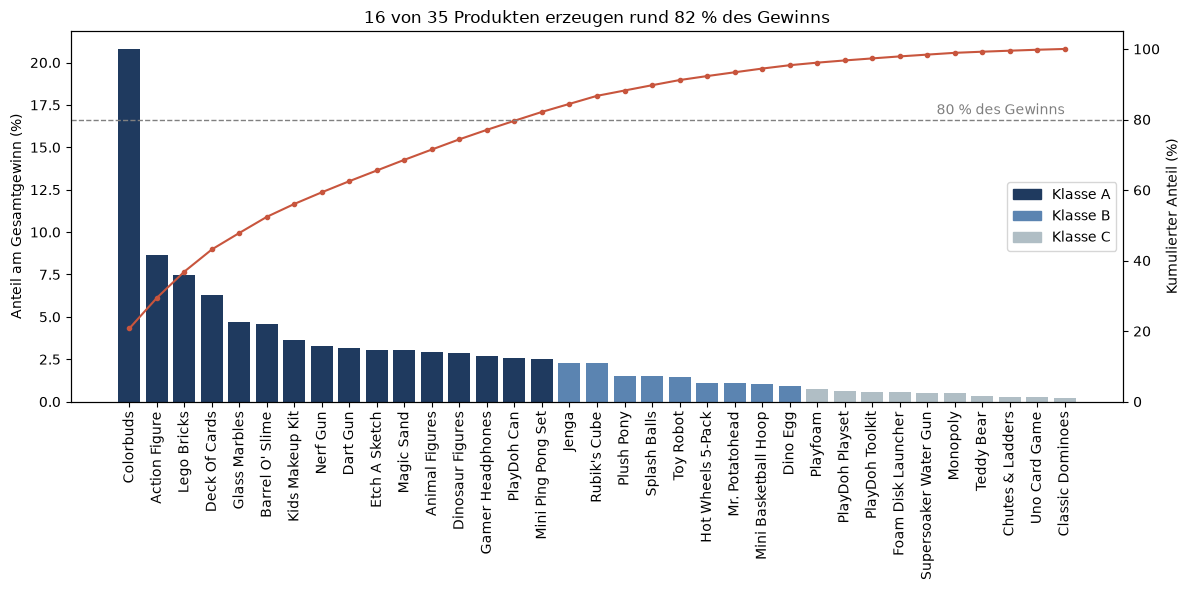

In [23]:
from pathlib import Path

from matplotlib.patches import Patch

Path("../docs/figures").mkdir(parents=True, exist_ok=True)

class_colors = {"A": "#1F3A5F", "B": "#5B84B1", "C": "#B0BEC5"}
bar_colors = product_profit["ABC_Class"].astype(str).map(class_colors).tolist()

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.bar(product_profit["Product_Name"], product_profit["Share_Pct"], color=bar_colors)
ax1.set_ylabel("Anteil am Gesamtgewinn (%)")
ax1.tick_params(axis="x", rotation=90)

ax2 = ax1.twinx()
ax2.plot(product_profit["Product_Name"], product_profit["Cumulative_Pct"],
         color="#C8553D", marker="o", markersize=3)
ax2.axhline(80, color="grey", linestyle="--", linewidth=1)
ax2.text(len(product_profit) - 1, 81.5, "80 % des Gewinns", ha="right", color="grey")
ax2.set_ylabel("Kumulierter Anteil (%)")
ax2.set_ylim(0, 105)

ax1.legend(handles=[Patch(color=c, label=f"Klasse {k}") for k, c in class_colors.items()], loc="center right")
ax1.set_title("16 von 35 Produkten erzeugen rund 82 % des Gewinns")
plt.tight_layout()
plt.savefig("../docs/figures/pareto_abc.png", dpi=150)
plt.show()